# Accident Locations Germany 2025: EDA and Baseline Model

**Team:** The Random Forest Rangers | **Notebook owner:** Micheal

This notebook takes the German road accident atlas for 2025 from raw data to a first baseline model. It follows the structure: define the goal, get the data, clean it, split it, explore the training data, and set a baseline score to beat.

> This is a working notebook. Each team member keeps their own notebook, so we can compare ideas before merging them into one final notebook.

## Team Discussion: The Data at a Glance

### Dataset: German Road Accident Atlas 2025 (Unfallatlas)

| Item | Details |
|---|---|
| **Source** | Accident Atlas of the statistical offices of the Federation and the Länder (Destatis) |
| **File** | `data/Unfallorte_2025.csv` |
| **Size** | 273,007 accidents, 25 columns, all 12 months of 2025 |
| **Scope** | Only road accidents **with personal injury** (accidents with property damage only are not included) |
| **Codebook** | `data/DSB_Unfallatlas_EN.pdf` explains every code in every column |
| **Reading the file** | The separator is `;` and decimals use a comma (German format): `pd.read_csv(path, sep=";", decimal=",")` |

### Important Columns

| Group | Original columns (German) | English name in this notebook | Meaning |
|---|---|---|---|
| **Location** | `ULAND`, `UREGBEZ`, `UKREIS`, `UGEMEINDE` | `state`, `admin_region`, `district`, `municipality` | Federal state (1 to 16), administrative region, district, municipality |
| **Time** | `UMONAT`, `USTUNDE`, `UWOCHENTAG` | `month`, `hour`, `weekday` | Month, hour of day, day of week (1 = Sunday) |
| **🎯 Severity** | `UKATEGORIE` | `severity` | 1 = persons killed, 2 = seriously injured, 3 = slightly injured |
| **Accident kind / type** | `UART` (0 to 9), `UTYP1` (1 to 7) | `accident_kind`, `accident_type` | Head-on collision, collision with a pedestrian, leaving the carriageway, turning accident, ... |
| **Conditions** | `ULICHTVERH`, `IstStrassenzustand` | `light_condition`, `road_condition` | Light (daylight, twilight, darkness) and road surface (dry, wet, winter slippery) |
| **Participants** | `IstRad`, `IstPKW`, `IstFuss`, `IstKrad`, `IstGkfz`, `IstSonstige` | `involves_bicycle`, `involves_car`, `involves_pedestrian`, `involves_motorcycle`, `involves_goods_vehicle`, `involves_other` | 0 or 1: was at least one bicycle, car, pedestrian, motorcycle, goods vehicle, or other vehicle involved? |
| **Coordinates** | `LINREFX/Y` and `XGCSWGS84/YGCSWGS84` | `utm_x`, `utm_y`, `longitude`, `latitude` | The same location in two coordinate systems (UTM zone 32N and WGS84) |
| **Not useful as features** | `UIDENTSTLAE`, `UJAHR`, `PLST` | `accident_id`, `year`, `plausibility_level` | ID number, the year (always 2025), and a location quality check flag |

### Natural Target: `severity` (UKATEGORIE)

| Class | Meaning | Share of accidents |
|---|---|---|
| 3 | Slightly injured | **84.3%** |
| 2 | Seriously injured | **14.8%** |
| 1 | Persons killed | **0.9%** |

This is a **classification** problem with a **strong class imbalance**, which is exactly what the assignment warns about.

### Points to Discuss with the Team

- **Binary target option:** severe accident (class 1 or 2, about 15.7%) versus slight accident (class 3). This is easier to model and easier to explain to stakeholders. **This notebook uses the binary target `is_severe`.**
- **Baseline trap:** a model that always predicts "slight" reaches about **84% accuracy** but a **recall of 0** for severe accidents. Accuracy is misleading here, so we use **recall and F1 for the severe class**.
- **Possible stakeholders:** traffic police, road planning authorities, or emergency services who want to know which conditions make an accident severe.
- **Possible leakage:** columns such as `accident_kind` and `accident_type` are only recorded **after** the accident happened. That is fine if the goal is **understanding risk factors**, but not if the goal is **predicting before the accident**. We need to agree on the goal first.



## The Machine Learning Workflow

### Define the Business Goal

The stakeholder is a **road safety team** (for example traffic police or a road planning authority). They see thousands of injury accidents every year and want to focus prevention work and resources on the situations that end in **severe** outcomes (people killed or seriously injured).

We want to estimate, for an injury accident, whether it is **severe** from its circumstances: time, place, light, road surface, the type of road users involved, and the kind of accident. This helps the team understand which conditions drive severity and where to act first.

In data science terms this is a **binary classification** problem:

- **Target:** `is_severe` = 1 if `severity` is 1 (killed) or 2 (seriously injured), else 0.
- **Metric:** **F1 score for the severe class**, and we also watch **recall**. Missing a severe pattern (false negative) is costly, but flagging everything as severe (false positive) makes the model useless, so a balanced metric fits.

### Setup

We import the libraries once at the top and set a consistent plot style.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42

### Get the Data

The CSV uses `;` as separator and a comma as decimal mark. We read the ID column as text so the long numbers are not mangled.

In [2]:
DATA_PATH = "data/Unfallorte_2025.csv"

accidents = pd.read_csv(
    DATA_PATH,
    sep=";",
    decimal=",",
    dtype={"UIDENTSTLAE": str},
)
print(accidents.shape)

(273007, 25)


Let us preview the raw data with its original German column names.

In [3]:
accidents.head()

,UIDENTSTLAE,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UJAHR,UMONAT,USTUNDE,UWOCHENTAG,UKATEGORIE,UART,UTYP1,ULICHTVERH,IstStrassenzustand,IstRad,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstige,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84,PLST
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,5,3,0,0,0,1,0,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,0,7,0,0,1,0,0,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,5,3,0,1,0,1,0,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,6,2,0,0,0,1,1,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,2,6,0,0,1,0,0,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1


### Translate the Column Names to English

The original names are German abbreviations. We rename them to clear English snake_case names, following the codebook (`data/DSB_Unfallatlas_EN.pdf`). This is pure renaming, so it is always safe.

In [4]:
COLUMN_NAMES = {
    "UIDENTSTLAE": "accident_id",
    "ULAND": "state",
    "UREGBEZ": "admin_region",
    "UKREIS": "district",
    "UGEMEINDE": "municipality",
    "UJAHR": "year",
    "UMONAT": "month",
    "USTUNDE": "hour",
    "UWOCHENTAG": "weekday",
    "UKATEGORIE": "severity",
    "UART": "accident_kind",
    "UTYP1": "accident_type",
    "ULICHTVERH": "light_condition",
    "IstStrassenzustand": "road_condition",
    "IstRad": "involves_bicycle",
    "IstPKW": "involves_car",
    "IstFuss": "involves_pedestrian",
    "IstKrad": "involves_motorcycle",
    "IstGkfz": "involves_goods_vehicle",
    "IstSonstige": "involves_other",
    "LINREFX": "utm_x",
    "LINREFY": "utm_y",
    "XGCSWGS84": "longitude",
    "YGCSWGS84": "latitude",
    "PLST": "plausibility_level",
}

accidents = accidents.rename(columns=COLUMN_NAMES)
accidents.columns.tolist()

['accident_id',
 'state',
 'admin_region',
 'district',
 'municipality',
 'year',
 'month',
 'hour',
 'weekday',
 'severity',
 'accident_kind',
 'accident_type',
 'light_condition',
 'road_condition',
 'involves_bicycle',
 'involves_car',
 'involves_pedestrian',
 'involves_motorcycle',
 'involves_goods_vehicle',
 'involves_other',
 'utm_x',
 'utm_y',
 'longitude',
 'latitude',
 'plausibility_level']

The codes inside the columns are also numbers. We keep the numbers for modelling, but we store readable English labels in dictionaries so the plots are easy to understand.

In [5]:
STATE_LABELS = {
    1: "Schleswig-Holstein", 2: "Hamburg", 3: "Lower Saxony", 4: "Bremen",
    5: "North Rhine-Westphalia", 6: "Hesse", 7: "Rhineland-Palatinate",
    8: "Baden-Wuerttemberg", 9: "Bavaria", 10: "Saarland", 11: "Berlin",
    12: "Brandenburg", 13: "Mecklenburg-Vorpommern", 14: "Saxony",
    15: "Saxony-Anhalt", 16: "Thuringia",
}
WEEKDAY_LABELS = {
    1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat",
}
SEVERITY_LABELS = {1: "Killed", 2: "Seriously injured", 3: "Slightly injured"}
ACCIDENT_KIND_LABELS = {
    0: "Other kind",
    1: "With starting/stopping/stationary vehicle",
    2: "With vehicle ahead or waiting",
    3: "With vehicle moving sideways, same direction",
    4: "With oncoming vehicle",
    5: "With turning or crossing vehicle",
    6: "Vehicle and pedestrian",
    7: "With obstacle on the road",
    8: "Leaving the road to the right",
    9: "Leaving the road to the left",
}
ACCIDENT_TYPE_LABELS = {
    1: "Driving accident",
    2: "Turning off",
    3: "Turning into / crossing",
    4: "Pedestrian crossing",
    5: "Stationary traffic",
    6: "Moving in same lane",
    7: "Other",
}
LIGHT_LABELS = {0: "Daylight", 1: "Twilight", 2: "Darkness"}
ROAD_LABELS = {0: "Dry", 1: "Wet / damp", 2: "Winter slippery"}
PARTICIPANT_COLUMNS = [
    "involves_bicycle", "involves_car", "involves_pedestrian",
    "involves_motorcycle", "involves_goods_vehicle", "involves_other",
]

### First Look at the Data

A quick structural check shows the column types and where values are missing.

In [6]:
accidents.head()

,accident_id,state,admin_region,district,municipality,year,month,hour,weekday,severity,accident_kind,accident_type,light_condition,road_condition,involves_bicycle,involves_car,involves_pedestrian,involves_motorcycle,involves_goods_vehicle,involves_other,utm_x,utm_y,longitude,latitude,plausibility_level
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,5,3,0,0,0,1,0,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,0,7,0,0,1,0,0,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,5,3,0,1,0,1,0,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,6,2,0,0,0,1,1,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,2,6,0,0,1,0,0,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1


In [7]:
accidents.info()

<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 25 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   accident_id             273007 non-null  str    
 1   state                   273007 non-null  int64  
 2   admin_region            273007 non-null  int64  
 3   district                273007 non-null  int64  
 4   municipality            273007 non-null  int64  
 5   year                    273007 non-null  int64  
 6   month                   273007 non-null  int64  
 7   hour                    273007 non-null  int64  
 8   weekday                 273007 non-null  int64  
 9   severity                273007 non-null  int64  
 10  accident_kind           273007 non-null  int64  
 11  accident_type           273007 non-null  int64  
 12  light_condition         273007 non-null  int64  
 13  road_condition          273007 non-null  int64  
 14  involves_bicycle        273007 

In [8]:
print("Missing values in total:", int(accidents.isna().sum().sum()))
print("Duplicated rows:", int(accidents.duplicated().sum()))
print("Duplicated accident IDs:", int(accidents["accident_id"].duplicated().sum()))

Missing values in total: 0


Duplicated rows: 0
Duplicated accident IDs: 0


In [9]:
# Number of distinct values per column: low numbers mean coded categories
accidents.nunique().sort_values()

year                           1
involves_bicycle               2
involves_car                   2
plausibility_level             2
involves_other                 2
involves_goods_vehicle         2
involves_motorcycle            2
involves_pedestrian            2
road_condition                 3
light_condition                3
severity                       3
weekday                        7
accident_type                  7
admin_region                   9
accident_kind                 10
month                         12
state                         16
hour                          24
district                      87
municipality                 531
utm_x                     269470
utm_y                     269478
latitude                  269483
longitude                 269487
accident_id               273007
dtype: int64

The dataset has 273,007 accidents and 25 columns. The data is very clean: there are **no missing values**, no duplicated rows, and every accident ID is unique.

Almost every column is a **coded category** stored as an integer (for example `state` has 16 values and `accident_kind` has 10). Only the four coordinate columns are truly continuous. `year` has a single value (2025), so it carries no information.

## Clean the Data

These steps are all **leakage-safe**, so we do them before the split: they are fixed per-row rules that do not learn anything from the data.

In [10]:
# The two coordinate systems describe the same point. Check how strongly they agree.
coord_corr = accidents[["utm_x", "longitude"]].corr().iloc[0, 1], \
    accidents[["utm_y", "latitude"]].corr().iloc[0, 1]
print("Correlation utm_x vs longitude: %.3f" % coord_corr[0])
print("Correlation utm_y vs latitude:  %.3f" % coord_corr[1])

Correlation utm_x vs longitude: 0.999
Correlation utm_y vs latitude:  1.000


The UTM coordinates and the WGS84 coordinates are almost perfectly correlated, because they describe the same location. Keeping both would only add duplicate information, so we keep the easier to read `longitude` and `latitude`.

In [11]:
# Drop columns that carry no useful signal for the model
columns_to_drop = [
    "accident_id",          # unique ID, no pattern to learn
    "year",                 # always 2025
    "plausibility_level",   # data quality flag of the location check
    "utm_x", "utm_y",       # duplicate of longitude / latitude
]
accidents = accidents.drop(columns=columns_to_drop)
accidents.shape

(273007, 20)

Next we create the binary target. Classes 1 (killed) and 2 (seriously injured) become **severe**, class 3 (slightly injured) becomes **not severe**.

In [12]:
accidents["is_severe"] = (accidents["severity"] <= 2).astype(int)
accidents["is_severe"].value_counts(normalize=True).round(3)

is_severe
0    0.843
1    0.157
Name: proportion, dtype: float64

15.7% of the accidents are severe and 84.3% are not. The classes are clearly **imbalanced**, which we have to keep in mind for the split, the metric, and the models.

We now separate the target from the features. `severity` is the original three-class version of the target, so it must **not** be a feature (that would be target leakage). We keep it aside for the EDA only.

In [13]:
y = accidents["is_severe"]
severity = accidents["severity"]
X = accidents.drop(columns=["is_severe", "severity"])
X.columns.tolist()

['state',
 'admin_region',
 'district',
 'municipality',
 'month',
 'hour',
 'weekday',
 'accident_kind',
 'accident_type',
 'light_condition',
 'road_condition',
 'involves_bicycle',
 'involves_car',
 'involves_pedestrian',
 'involves_motorcycle',
 'involves_goods_vehicle',
 'involves_other',
 'longitude',
 'latitude']

## Train-Test Split

We hold out part of the data so we can judge the model on accidents it has never seen. From here on, anything we *fit* is learned on the training set only.

Because the target is imbalanced, we use a **stratified** split: the share of severe accidents stays the same in both sets.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " severe share: %.3f" % y_train.mean())
print("Test: ", X_test.shape, " severe share: %.3f" % y_test.mean())

Train: (218405, 19)  severe share: 0.157
Test:  (54602, 19)  severe share: 0.157


The 273,007 accidents are split into 218,405 for training and 54,602 for testing. Thanks to stratification, both sets have exactly 15.7% severe accidents.

## Explore the Training Data

Now we explore the **training set** only, so that nothing we learn here is influenced by the test set. We join the features with the target into one table to make the plots easier.

In [15]:
train = X_train.copy()
train["is_severe"] = y_train
train["severity"] = severity.loc[X_train.index]
overall_severe_rate = train["is_severe"].mean()
print("Overall severe rate in training data: %.1f%%" % (100 * overall_severe_rate))

Overall severe rate in training data: 15.7%


In [16]:
def plot_severe_rate(data, column, labels=None, ax=None, horizontal=False, sort=False):
    """Bar plot of the share of severe accidents per category, with the overall rate."""
    stats = data.groupby(column)["is_severe"].agg(["mean", "size"])
    if labels is not None:
        stats.index = stats.index.map(labels)
    if sort:
        stats = stats.sort_values("mean")
    stats["mean"] *= 100
    ax = ax or plt.gca()
    if horizontal:
        ax.barh(stats.index.astype(str), stats["mean"], color="tab:red", alpha=0.75)
        ax.axvline(100 * overall_severe_rate, color="black", linestyle="--", label="overall")
        ax.set_xlabel("Severe accidents (%)")
    else:
        ax.bar(stats.index.astype(str), stats["mean"], color="tab:red", alpha=0.75)
        ax.axhline(100 * overall_severe_rate, color="black", linestyle="--", label="overall")
        ax.set_ylabel("Severe accidents (%)")
    ax.legend()
    return stats

### The Target

First we look at how the accidents split across the three original severity classes and the binary target.

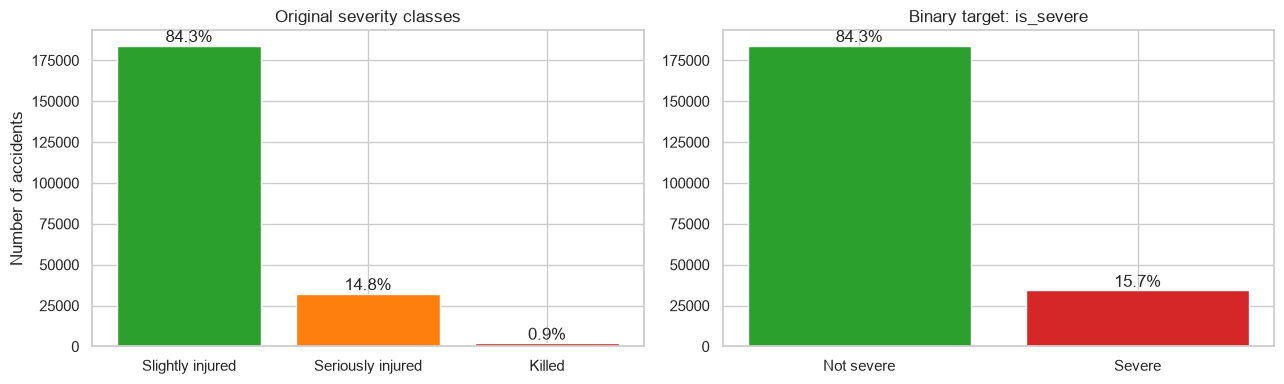

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

severity_counts = train["severity"].map(SEVERITY_LABELS).value_counts()
axes[0].bar(severity_counts.index, severity_counts.values,
            color=["tab:green", "tab:orange", "tab:red"])
axes[0].set_title("Original severity classes")
axes[0].set_ylabel("Number of accidents")
for i, value in enumerate(severity_counts.values):
    axes[0].text(i, value, f"{value / len(train):.1%}", ha="center", va="bottom")

binary_counts = train["is_severe"].map({0: "Not severe", 1: "Severe"}).value_counts()
axes[1].bar(binary_counts.index, binary_counts.values, color=["tab:green", "tab:red"])
axes[1].set_title("Binary target: is_severe")
for i, value in enumerate(binary_counts.values):
    axes[1].text(i, value, f"{value / len(train):.1%}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

Only about 0.9% of injury accidents are fatal and about 14.8% have seriously injured people. Combining both gives the 15.7% severe class. Predicting fatal accidents alone would be extremely hard with so few examples, which is another reason for the binary target.

### When Do Accidents Happen?

We look at the number of accidents and the share of severe accidents over the hours of the day, the days of the week, and the months.

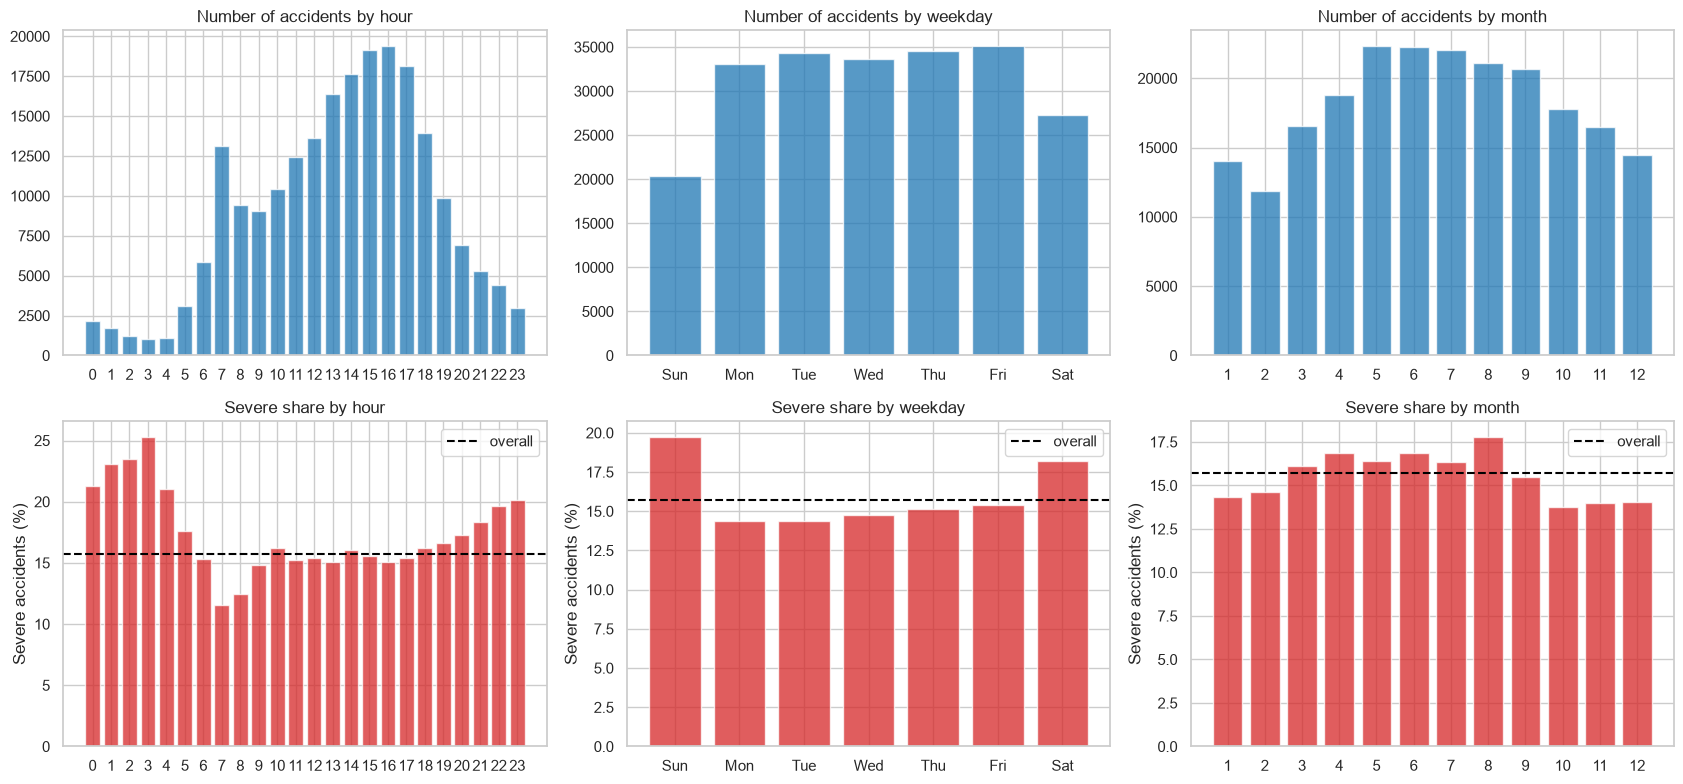

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))

for col, (column, labels) in enumerate(
    [("hour", None), ("weekday", WEEKDAY_LABELS), ("month", None)]
):
    counts = train[column].value_counts().sort_index()
    index = counts.index.map(labels) if labels else counts.index
    axes[0, col].bar(index.astype(str), counts.values, color="tab:blue", alpha=0.75)
    axes[0, col].set_title(f"Number of accidents by {column}")
    plot_severe_rate(train, column, labels, ax=axes[1, col])
    axes[1, col].set_title(f"Severe share by {column}")

plt.tight_layout()
plt.show()

- **Hour:** most accidents happen during the afternoon rush hour (14:00 to 17:00) and the morning peak at 07:00. But the **severe share is highest at night**: 21% to 25% between 00:00 and 04:00, versus only 11.6% at 07:00. Fewer accidents happen at night, but they are more often severe (higher speeds, less traffic, possibly alcohol and fatigue).

- **Hour:** most accidents happen during the day, with peaks at 07:00 (morning commute) and between 14:00 and 17:00 (afternoon rush hour). The **severe share** tells a different story: it rises above the overall average (15.7%) from about **18:00 and stays above it until 05:00**, peaking at **21% to 25% between 00:00 and 04:00**. The lowest severe share is at 07:00 (11.6%). Note that this is a share, not a count: 07:00 still has about 1,500 severe accidents in the training set, far more than 03:00 (about 260), simply because so many more accidents happen then. At night there are fewer accidents, but each one is more likely to be severe (higher speeds, less traffic, possibly alcohol and fatigue).


- **Weekday:** Monday to Friday have the most accidents (commuting), but **Sunday (19.7%) and Saturday (18.2%)** have the highest severe share. Weekday traffic causes many minor collisions, weekend traffic causes fewer but more serious ones.
- **Month:** summer months have more accidents and a slightly higher severe share (August 17.8%) than winter months (about 14%). A likely reason is more motorcycle and leisure traffic in summer.

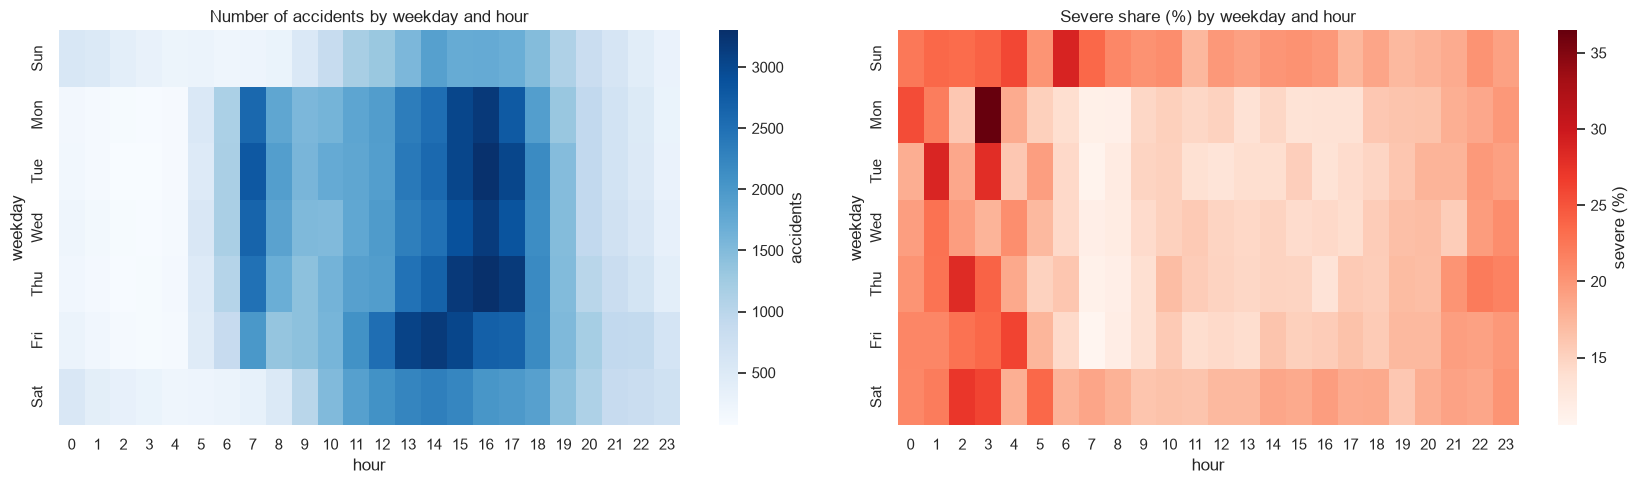

In [19]:
# Heatmap: when in the week do accidents and severe accidents happen?
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

counts = train.pivot_table(index="weekday", columns="hour", values="is_severe", aggfunc="size")
counts.index = counts.index.map(WEEKDAY_LABELS)
sns.heatmap(counts, cmap="Blues", ax=axes[0], cbar_kws={"label": "accidents"})
axes[0].set_title("Number of accidents by weekday and hour")

rates = train.pivot_table(index="weekday", columns="hour", values="is_severe", aggfunc="mean") * 100
rates.index = rates.index.map(WEEKDAY_LABELS)
sns.heatmap(rates, cmap="Reds", ax=axes[1], cbar_kws={"label": "severe (%)"})
axes[1].set_title("Severe share (%) by weekday and hour")

plt.tight_layout()
plt.show()

The left heatmap shows the weekday commuting pattern: the busiest slots are weekday afternoons around 15:00 to 16:00 (about 3,300 accidents each). The right heatmap shows the opposite picture for severity: the darkest cells are **nights, especially the early hours of the weekend**. Single cells at night are based on fewer accidents, so their values are noisier.

### Light and Road Conditions

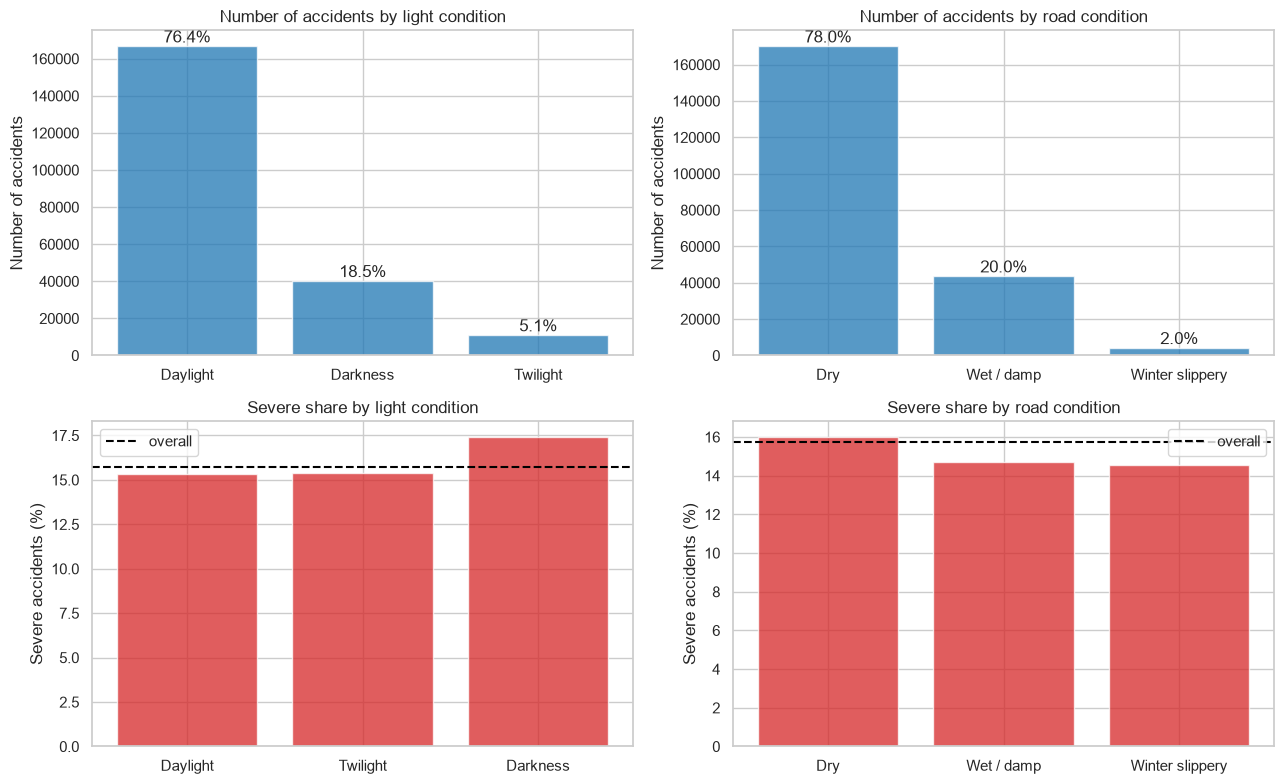

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for col, (column, labels, title) in enumerate([
    ("light_condition", LIGHT_LABELS, "light condition"),
    ("road_condition", ROAD_LABELS, "road condition"),
]):
    # Top row: how many accidents happen in each condition
    counts = train[column].map(labels).value_counts()
    axes[0, col].bar(counts.index, counts.values, color="tab:blue", alpha=0.75)
    axes[0, col].set_title(f"Number of accidents by {title}")
    axes[0, col].set_ylabel("Number of accidents")
    for i, value in enumerate(counts.values):
        axes[0, col].text(i, value, f"{value / len(train):.1%}", ha="center", va="bottom")

    # Bottom row: how often an accident in each condition is severe
    plot_severe_rate(train, column, labels, ax=axes[1, col])
    axes[1, col].set_title(f"Severe share by {title}")

plt.tight_layout()
plt.show()

- **Light:** 76% of accidents happen in daylight. Accidents in **darkness** are a bit more often severe (17.4% versus 15.3% in daylight).
- **Road:** 78% of accidents happen on dry roads. Surprisingly, wet and winter-slippery roads have a slightly *lower* severe share (about 14.5%) than dry roads (16.0%). A likely explanation is that people drive more slowly and carefully in bad conditions, while dry roads invite higher speeds.

Both effects are small, so these features alone will not separate severe from non-severe accidents well.

### Who Was Involved?

Each participant column is 1 if at least one road user of that type was involved. We compare the severe share when that road user is involved versus not involved.

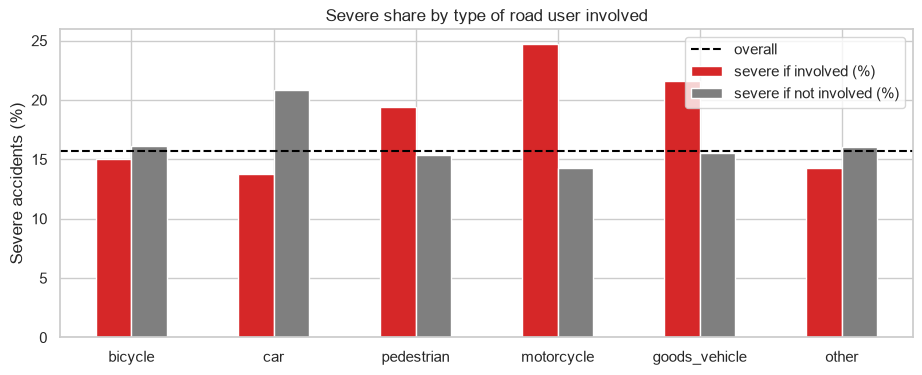

,involved (%),severe if involved (%),severe if not involved (%)
bicycle,32.8,15.0,16.1
car,72.3,13.8,20.8
pedestrian,8.8,19.4,15.4
motorcycle,13.5,24.7,14.3
goods_vehicle,4.0,21.6,15.5
other,14.5,14.3,16.0


In [21]:
participant_stats = pd.DataFrame({
    "involved (%)": [100 * train[c].mean() for c in PARTICIPANT_COLUMNS],
    "severe if involved (%)": [
        100 * train.loc[train[c] == 1, "is_severe"].mean() for c in PARTICIPANT_COLUMNS
    ],
    "severe if not involved (%)": [
        100 * train.loc[train[c] == 0, "is_severe"].mean() for c in PARTICIPANT_COLUMNS
    ],
}, index=[c.replace("involves_", "") for c in PARTICIPANT_COLUMNS]).round(1)

participant_stats[["severe if involved (%)", "severe if not involved (%)"]].plot.bar(
    figsize=(11, 4), color=["tab:red", "tab:gray"], rot=0
)
plt.axhline(100 * overall_severe_rate, color="black", linestyle="--", label="overall")
plt.ylabel("Severe accidents (%)")
plt.title("Severe share by type of road user involved")
plt.legend()
plt.show()

participant_stats

- **Motorcycles** are the strongest signal: when a motorcycle is involved, **24.7%** of accidents are severe, compared with 14.3% without one. Riders have almost no protection.
- **Goods vehicles** (21.6%) and **pedestrians** (19.4%) also raise the severe share: heavy mass on one side, no protection on the other.
- **Cars** lower it: 13.8% with a car involved versus 20.8% without. Car occupants are well protected, and many car accidents are minor rear-end collisions.
- **Bicycles** are involved in about a third of all accidents, but their severe share (15.0%) is close to average.

### Kind and Type of Accident

`accident_kind` describes the collision itself, `accident_type` describes the traffic situation that led to it.

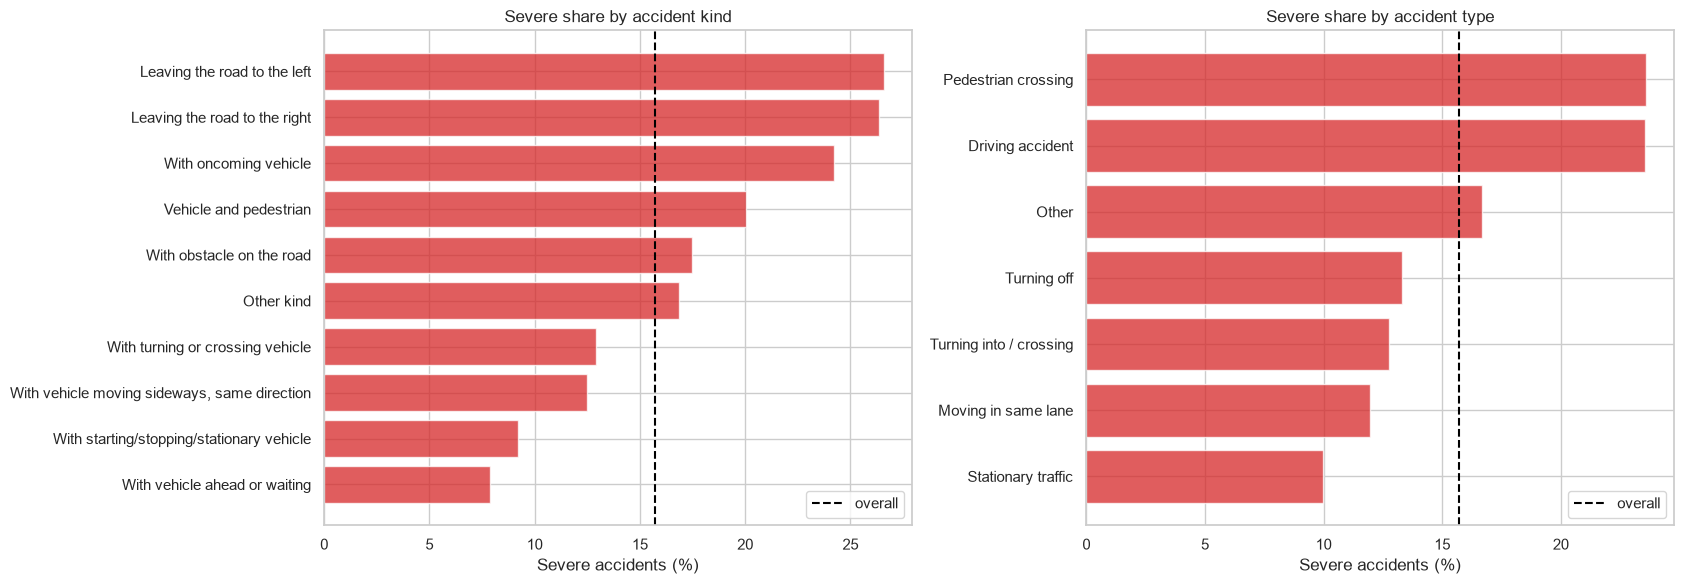

accident_kind
With turning or crossing vehicle                0.266
Other kind                                      0.184
With vehicle ahead or waiting                   0.155
Leaving the road to the right                   0.078
Vehicle and pedestrian                          0.078
With oncoming vehicle                           0.070
With starting/stopping/stationary vehicle       0.056
With vehicle moving sideways, same direction    0.056
Leaving the road to the left                    0.047
With obstacle on the road                       0.011
Name: proportion, dtype: float64

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
plot_severe_rate(train, "accident_kind", ACCIDENT_KIND_LABELS, ax=axes[0], horizontal=True, sort=True)
axes[0].set_title("Severe share by accident kind")
plot_severe_rate(train, "accident_type", ACCIDENT_TYPE_LABELS, ax=axes[1], horizontal=True, sort=True)
axes[1].set_title("Severe share by accident type")
plt.tight_layout()
plt.show()

train["accident_kind"].map(ACCIDENT_KIND_LABELS).value_counts(normalize=True).round(3)

- The most severe kinds are **leaving the road** (to the left 26.6%, to the right 26.4%) and **collisions with oncoming vehicles** (24.2%). These are typical high-speed accidents, often on rural roads.
- **Vehicle and pedestrian** collisions are also above average (20.0%).
- The least severe kinds are **rear-end collisions** with a vehicle ahead or waiting (7.9%) and collisions with starting or stopping vehicles (9.2%): low speed, mostly in towns.
- For the accident type, **driving accidents** (losing control) and **pedestrian crossing** accidents are the most severe (both 23.6%).

⚠️ These are the strongest signals so far, but remember the leakage question: kind and type are only known after the accident happened.

### Where Do Accidents Happen?

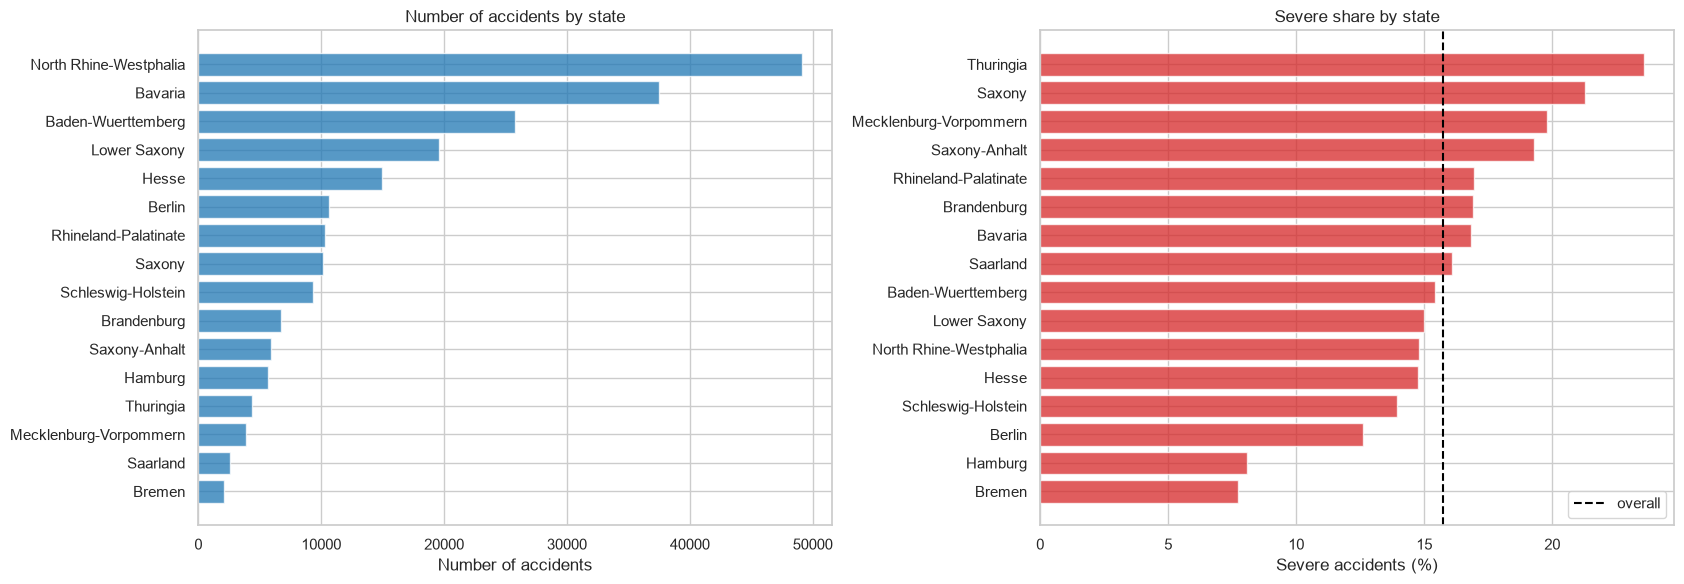

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

state_counts = train["state"].map(STATE_LABELS).value_counts().sort_values()
axes[0].barh(state_counts.index, state_counts.values, color="tab:blue", alpha=0.75)
axes[0].set_title("Number of accidents by state")
axes[0].set_xlabel("Number of accidents")

plot_severe_rate(train, "state", STATE_LABELS, ax=axes[1], horizontal=True, sort=True)
axes[1].set_title("Severe share by state")

plt.tight_layout()
plt.show()

- North Rhine-Westphalia and Bavaria have by far the most accidents, simply because they are the largest states.
- The severe share shows a clear **urban versus rural** pattern: the city states **Bremen (7.7%), Hamburg (8.1%) and Berlin (12.6%)** have the lowest severe shares, while the more rural eastern states **Thuringia (23.6%), Saxony (21.3%) and Mecklenburg-Vorpommern (19.8%)** have the highest. In cities, speeds are low; on rural roads, they are high.

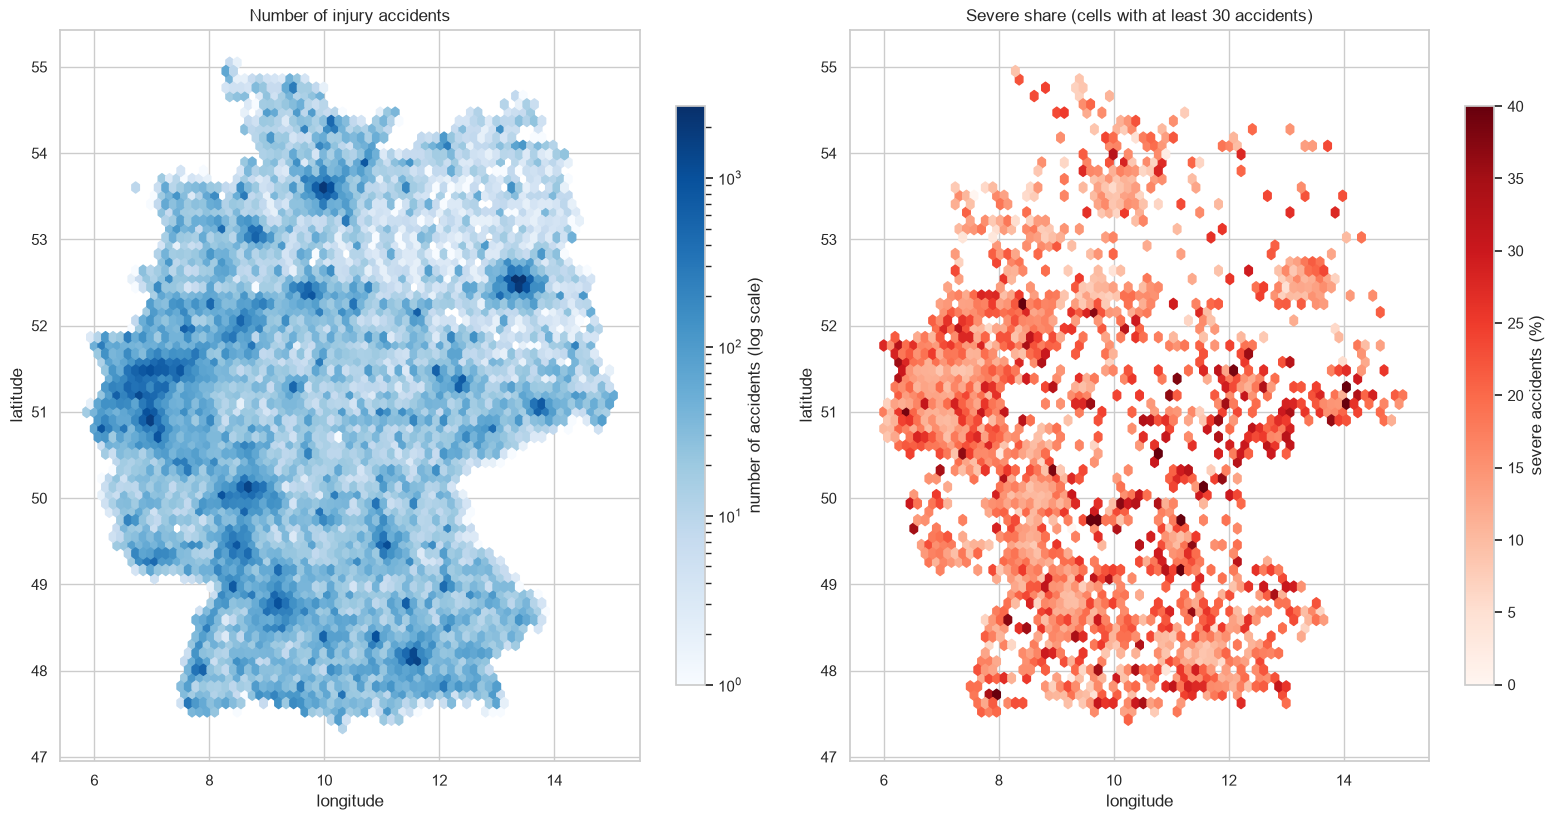

In [24]:
# Two maps: where accidents happen (left) and where they tend to be severe (right)
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

hb = axes[0].hexbin(train["longitude"], train["latitude"], gridsize=70, bins="log",
                    cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="number of accidents (log scale)", shrink=0.6)
axes[0].set_title("Number of injury accidents")

hb = axes[1].hexbin(train["longitude"], train["latitude"], C=train["is_severe"] * 100,
                    reduce_C_function=np.mean, gridsize=70, cmap="Reds", mincnt=30,
                    vmin=0, vmax=40)
fig.colorbar(hb, ax=axes[1], label="severe accidents (%)", shrink=0.6)
axes[1].set_title("Severe share (cells with at least 30 accidents)")

for ax in axes:
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    ax.set_aspect(1.5)
plt.tight_layout()
plt.show()

The left map shows that accidents cluster in cities and metropolitan areas (Berlin, Hamburg, Munich, the Ruhr area, Frankfurt). The right map shows the severe share: city centres are pale (low severe share), while **rural areas between the cities are darker red**. This confirms the urban versus rural pattern from the state plot, and suggests that location features (or a later "urban / rural" feature) can help the model.

### Which Features Are Related to Each Other?

Most of our columns are **categories stored as numbers** (for example `state` 1 to 16 or `accident_kind` 0 to 9). For such columns a normal (Pearson) correlation is misleading, because the order of the codes means nothing. So we use two views:

1. **Pearson correlation** for the binary and truly numeric columns (participants, coordinates, hour, month, target).
2. **Cramér's V** for all columns treated as categories. Cramér's V measures how strongly two categorical variables are associated, from 0 (no association) to 1 (perfect association), and it does not depend on the order of the codes.

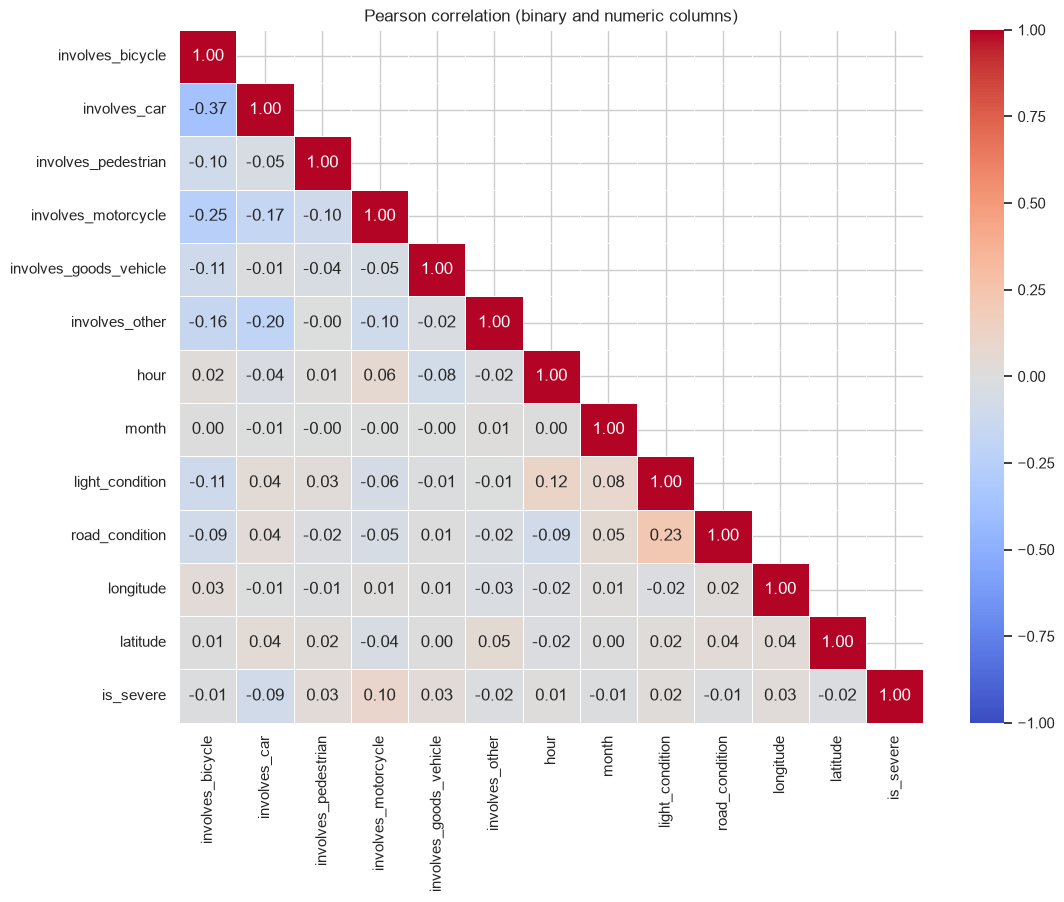

In [25]:
numeric_columns = PARTICIPANT_COLUMNS + [
    "hour", "month", "light_condition", "road_condition", "longitude", "latitude", "is_severe",
]
pearson = train[numeric_columns].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
sns.heatmap(pearson, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson correlation (binary and numeric columns)")
plt.show()

- All correlations are weak (below 0.4 in absolute value), so there is **no strong multicollinearity** between these columns.
- The strongest pair is `involves_bicycle` and `involves_car` (-0.37): many bicycle accidents happen without a car (single bicycle accidents or bicycle versus bicycle). `involves_bicycle` and `involves_motorcycle` (-0.25) behave similarly.
- `light_condition` and `road_condition` are mildly related (0.23): dark hours are more often wet or icy, especially in winter.
- With the target, only `involves_motorcycle` (+0.10) and `involves_car` (-0.09) show a visible linear correlation. A weak linear correlation does not mean the feature is useless: categorical effects (like the hour or the state) do not show up well in a Pearson correlation.

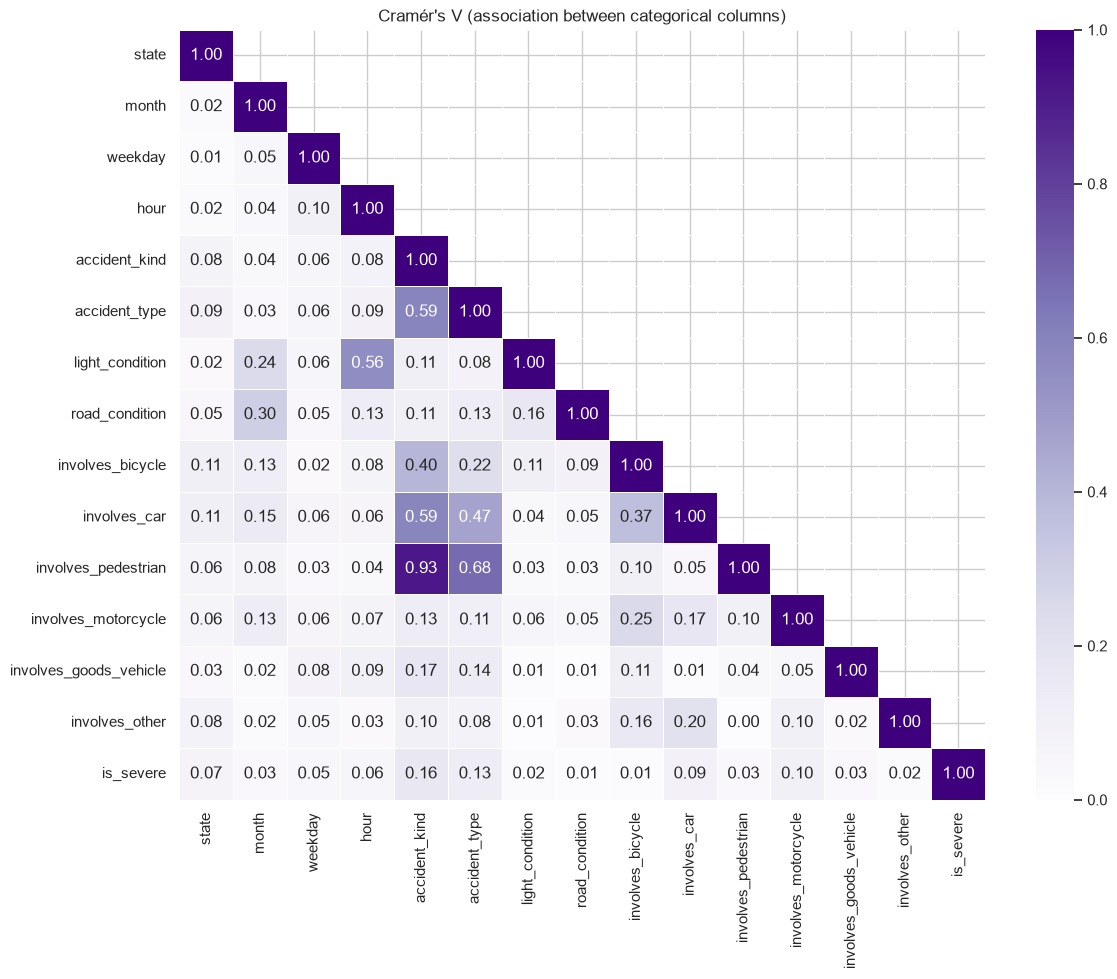

In [26]:
from scipy.stats import chi2_contingency


def cramers_v(x, y):
    """Bias-corrected Cramer's V between two categorical series."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    r, k = table.shape
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))


categorical_columns = [
    "state", "month", "weekday", "hour", "accident_kind", "accident_type",
    "light_condition", "road_condition",
] + PARTICIPANT_COLUMNS + ["is_severe"]

cramers = pd.DataFrame(index=categorical_columns, columns=categorical_columns, dtype=float)
for i, a in enumerate(categorical_columns):
    for b in categorical_columns[i:]:
        value = 1.0 if a == b else cramers_v(train[a], train[b])
        cramers.loc[a, b] = cramers.loc[b, a] = value

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(cramers, dtype=bool), k=1)
sns.heatmap(cramers, mask=mask, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1,
            linewidths=0.5)
plt.title("Cramér's V (association between categorical columns)")
plt.show()

In [27]:
# The strongest associations between pairs of features (target excluded)
features_only = cramers.drop(index="is_severe", columns="is_severe")
pairs = (
    features_only.where(np.triu(np.ones(features_only.shape, dtype=bool), k=1))
    .stack()
    .sort_values(ascending=False)
    .rename("cramers_v")
)
pairs.head(10).round(3)

accident_kind     involves_pedestrian    0.925
accident_type     involves_pedestrian    0.678
accident_kind     accident_type          0.591
                  involves_car           0.587
hour              light_condition        0.556
accident_type     involves_car           0.471
accident_kind     involves_bicycle       0.400
involves_bicycle  involves_car           0.368
month             road_condition         0.300
involves_bicycle  involves_motorcycle    0.251
Name: cramers_v, dtype: float64

- `accident_kind` and `involves_pedestrian` are almost the same information (Cramér's V 0.93): `accident_kind` = 6 means "vehicle and pedestrian". `accident_type` is also strongly linked to pedestrians (0.68, the type "pedestrian crossing").
- `accident_kind` and `accident_type` are related (0.59), because both describe how the accident happened.
- `hour` and `light_condition` are related (0.56), as expected: night means darkness.
- `month` and `road_condition` are related (0.30): winter months bring wet and slippery roads.

For tree-based models these overlaps are not a big problem. For linear models (for example Logistic Regression) we should keep the redundancy in mind, for example by dropping one of two almost identical features.

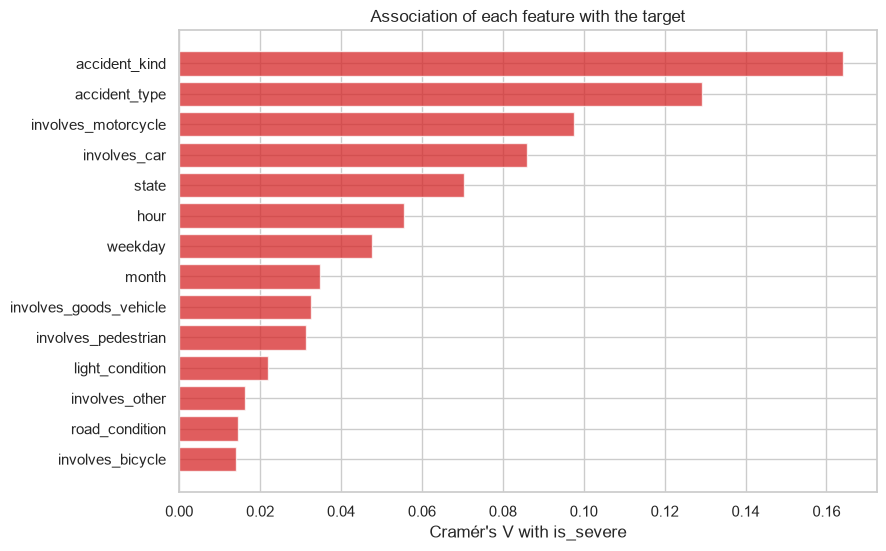

In [28]:
# How strongly is each feature associated with the target?
target_association = cramers["is_severe"].drop("is_severe").sort_values()

plt.figure(figsize=(9, 6))
plt.barh(target_association.index, target_association.values, color="tab:red", alpha=0.75)
plt.xlabel("Cramér's V with is_severe")
plt.title("Association of each feature with the target")
plt.show()

`accident_kind` (0.16) and `accident_type` (0.13) have the strongest association with severity, followed by `involves_motorcycle`, `involves_car`, `state`, and `hour`. All values are small: **no single feature separates severe from non-severe accidents well**. The model will need to combine many weak signals, which is a good use case for tree-based ensembles.

### EDA Summary

- **Target:** 15.7% of injury accidents are severe, so the data is imbalanced.
- **Time:** night hours and weekends have the highest severe share, even though most accidents happen at weekday rush hours.
- **Road users:** motorcycles, goods vehicles, and pedestrians raise the risk of a severe outcome; cars lower it.
- **Accident kind:** leaving the road and head-on collisions are the most severe; rear-end collisions are the least severe.
- **Place:** rural areas and eastern states have a higher severe share than city states.
- **Relationships:** most features are only weakly related to each other; the main overlaps are `accident_kind` with `involves_pedestrian`, and `hour` with `light_condition`.

## Feature Engineering

**Our data has no missing values**, so no imputation is needed and there is nothing to fit at this stage.

For the baseline we use the features as they are. In the next iterations, feature engineering will include:

- **One-hot encoding** for nominal codes such as `state`, `accident_kind`, `accident_type`, `weekday`.
- **Cyclic encoding** (sine and cosine) for `hour` and `month`, so that 23:00 and 00:00 are close to each other.
- New features suggested by the EDA, for example `is_weekend`, `is_night`, or an urban / rural indicator.
- Deciding whether to keep `accident_kind` and `accident_type` (leakage question above). 
- **Possible leakage:** columns such as `accident_kind` and `accident_type` are only recorded **after** the accident happened. That is fine if the goal is **understanding risk factors**, but not if the goal is **predicting before the accident**. We need to agree on the goal first.

Any encoder that learns from the data (for example a target encoder for districts) must be fitted on the training set only.

In [29]:
# Confirm that there is nothing to impute in the training or test features
print("Missing values in X_train:", int(X_train.isna().sum().sum()))
print("Missing values in X_test: ", int(X_test.isna().sum().sum()))

Missing values in X_train: 0
Missing values in X_test:  0


## Baseline Model

Before training a real model, we set a **baseline**: the simplest rule that makes a prediction. It gives us a score to beat. We use two baselines:

1. **Majority class:** always predict the most common class ("not severe").
2. **Heuristic rule from the EDA:** predict "severe" for the situations that the EDA showed to be most dangerous.

In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score, recall_score,
)


def evaluate(name, y_true, y_pred):
    """Return the main scores for the severe class as a dictionary."""
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }

### Baseline 1: Always Predict "Not Severe"

In [31]:
majority = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
majority_pred = majority.predict(X_test)

results = [evaluate("Majority class", y_test, majority_pred)]
pd.DataFrame(results).round(3)

,model,accuracy,precision,recall,f1
0,Majority class,0.843,0.0,0.0,0.0


The majority baseline reaches **84.3% accuracy**, but its **recall, precision and F1 for severe accidents are all 0**: it never finds a single severe accident. This is the accuracy trap from the team discussion, and it shows why accuracy is not our metric.

### Baseline 2: Heuristic Rule from the EDA

From the EDA, three situations stand out as the most dangerous:

- a **motorcycle** is involved (24.7% severe),
- a **pedestrian** is involved (19.4% severe),
- the accident kind is **head-on** (kind 4) or **leaving the road** (kinds 8 and 9), at 24% to 27% severe.

The rule predicts "severe" if at least one of these is true.

In [32]:
def heuristic_rule(data):
    """Predict a severe accident for the high-risk situations found in the EDA."""
    return (
        (data["involves_motorcycle"] == 1)
        | (data["involves_pedestrian"] == 1)
        | (data["accident_kind"].isin([4, 8, 9]))
    ).astype(int)


# Check the rule on the training data first (the test set stays untouched)
train_scores = evaluate("Heuristic rule (train)", y_train, heuristic_rule(X_train))
pd.DataFrame([train_scores]).round(3)

,model,accuracy,precision,recall,f1
0,Heuristic rule (train),0.635,0.227,0.551,0.322


In [33]:
heuristic_pred = heuristic_rule(X_test)
results.append(evaluate("Heuristic rule", y_test, heuristic_pred))
baseline_results = pd.DataFrame(results).set_index("model").round(3)
baseline_results

,accuracy,precision,recall,f1
model,,,,
Majority class,0.843,0.000,0.00,0.000
Heuristic rule,0.638,0.229,0.55,0.323


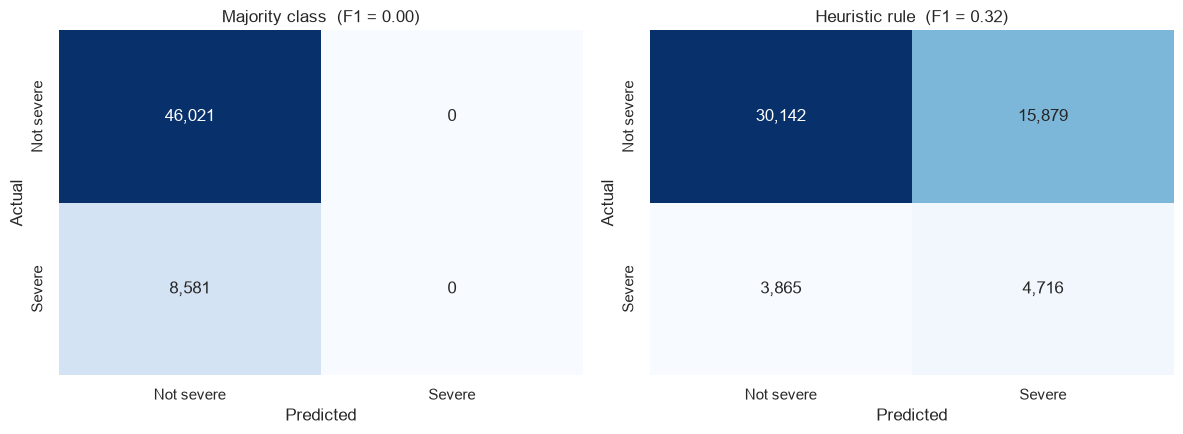

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pred) in zip(axes, [("Majority class", majority_pred),
                                   ("Heuristic rule", heuristic_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{name}  (F1 = {f1_score(y_test, pred):.2f})")
plt.tight_layout()
plt.show()

The heuristic rule finds **55% of the severe accidents** (recall 0.55) with a **precision of 0.23** (about 1 in 4 flagged accidents is really severe), giving an **F1 score of 0.32** on the test set. The scores on the training set are almost identical, so the rule is stable.

Its accuracy (64%) is lower than the majority baseline, but it is much more useful: it actually finds severe accidents. **F1 = 0.32 is the score our machine learning models have to beat.**

## Data Leakage Check: Which Columns Can We Use?

Baseline 2 uses `accident_kind` (kinds 4, 8 and 9). This column is only recorded **after** the accident happened. If our goal is to predict **before** an accident, the rule uses information that would not be available at prediction time, which is **data leakage**.

**Golden rule:** the baseline must use the **same features** as our models. Otherwise the comparison is not fair.

The answer depends on one question: **when do we make the prediction?** Every row in this dataset is an accident that already happened, so we can never predict *whether* an accident will happen (we have no rows without accidents). The real question is: **what information do we have at the moment of prediction?**

| Scenario | When do we predict? | `accident_kind` / `accident_type` | Participants (motorcycle, pedestrian, ...) |
|---|---|---|---|
| **A: Emergency services** | At the moment of the emergency call, right after the accident | ✅ known from the call | ✅ known |
| **B: Understanding risk factors** | Analysis after the accidents happened | ✅ allowed | ✅ allowed |
| **C: Before the accident** (road planning, warnings) | Before it happens | ❌ **leakage**, must be dropped | ✅ **kept** |

### Why Participants Stay in Scenario C, but Accident Kind Does Not

In scenario C we ask a **"what if"** question:

> *"**If** an accident involving a motorcycle happens at this place, at this hour, on a wet road, how likely is it to be severe?"*

Here the participants are **inputs we set ourselves** to ask the question, not something we wait to observe. A road planner can know them in advance, for example "this road has a lot of motorcycle traffic at weekends" or "this crossing has many pedestrians".

| | **Participants** | **`accident_kind` / `accident_type`** |
|---|---|---|
| Describes | **Who** is on the road | **How** the accident happened |
| Known before the accident? | ✅ Can be assumed (traffic mix, type of road) | ❌ It is the result of the accident itself |
| Example | "An accident involving a pedestrian" | "The car left the road to the left" |
| In scenario C | ✅ **Keep** | ❌ **Drop** |

`accident_kind` describes **what happened during the accident itself** (leaving the road, head-on collision), and that is very directly linked to severity. That is why it causes leakage, and the participants do not.

### Heuristic Rules Without Post-Accident Columns

We compare several simple rules that do **not** use `accident_kind` or `accident_type`. We score them on the **training set only**, so the test set stays untouched while we choose the rule.

In [35]:
night = X_train["hour"].isin([22, 23, 0, 1, 2, 3, 4, 5])
weekend = X_train["weekday"].isin([1, 7])
eastern_states = X_train["state"].isin([13, 14, 15, 16])
motorcycle = X_train["involves_motorcycle"] == 1
pedestrian = X_train["involves_pedestrian"] == 1

candidate_rules = {
    "Current rule: motorcycle | pedestrian | kind 4/8/9 (uses accident_kind)":
        motorcycle | pedestrian | X_train["accident_kind"].isin([4, 8, 9]),
    "motorcycle | pedestrian": motorcycle | pedestrian,
    "motorcycle | pedestrian | goods vehicle":
        motorcycle | pedestrian | (X_train["involves_goods_vehicle"] == 1),
    "motorcycle | pedestrian | night": motorcycle | pedestrian | night,
    "motorcycle | pedestrian | night | weekend": motorcycle | pedestrian | night | weekend,
    "motorcycle | pedestrian | no car":
        motorcycle | pedestrian | (X_train["involves_car"] == 0),
    "Conditions only: night | weekend | eastern states": night | weekend | eastern_states,
}

rule_scores = pd.DataFrame(
    [evaluate(name, y_train, rule.astype(int)) for name, rule in candidate_rules.items()]
).set_index("model").drop(columns="accuracy").round(3)
rule_scores

,precision,recall,f1
model,,,
Current rule: motorcycle | pedestrian | kind 4/8/9 (uses accident_kind),0.227,0.551,0.322
motorcycle | pedestrian,0.226,0.318,0.264
motorcycle | pedestrian | goods vehicle,0.222,0.364,0.276
motorcycle | pedestrian | night,0.219,0.403,0.284
motorcycle | pedestrian | night | weekend,0.198,0.540,0.290
motorcycle | pedestrian | no car,0.211,0.545,0.304
Conditions only: night | weekend | eastern states,0.191,0.429,0.265


When we remove `accident_kind`, the F1 score drops from **0.32** to about **0.30** at best. This shows that the column carries strong information, and that is exactly why leakage is dangerous: it gives **better-looking scores than reality**.

The best rule without post-accident columns is **"motorcycle OR pedestrian OR no car involved"** (F1 ≈ 0.30 on the training set). It only uses the participants, so it is valid in all three scenarios.

### Baseline 3: Heuristic Rule Without Leakage

The rule predicts "severe" if at least one of these is true:

- a **motorcycle** is involved (24.7% severe),
- a **pedestrian** is involved (19.4% severe),
- **no passenger car** is involved (20.8% severe, versus 13.8% when a car is involved).

In [36]:
def heuristic_rule_no_leakage(data):
    """Predict a severe accident without post-accident columns (accident_kind / type)."""
    return (
        (data["involves_motorcycle"] == 1)
        | (data["involves_pedestrian"] == 1)
        | (data["involves_car"] == 0)
    ).astype(int)


# Check the rule on the training data first (the test set stays untouched)
train_scores_b3 = evaluate("Heuristic rule without leakage (train)", y_train,
                           heuristic_rule_no_leakage(X_train))
pd.DataFrame([train_scores_b3]).round(3)

,model,accuracy,precision,recall,f1
0,Heuristic rule without leakage (train),0.608,0.211,0.545,0.304


In [37]:
no_leakage_pred = heuristic_rule_no_leakage(X_test)
results.append(evaluate("Heuristic rule without leakage", y_test, no_leakage_pred))
baseline_results = pd.DataFrame(results).set_index("model").round(3)
baseline_results

,accuracy,precision,recall,f1
model,,,,
Majority class,0.843,0.000,0.00,0.000
Heuristic rule,0.638,0.229,0.55,0.323
Heuristic rule without leakage,0.611,0.211,0.54,0.304


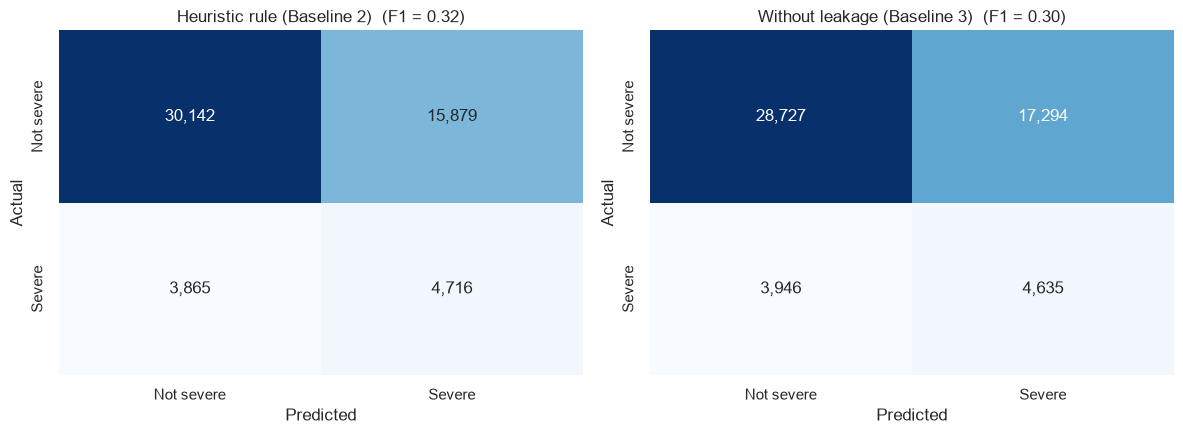

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pred) in zip(axes, [("Heuristic rule (Baseline 2)", heuristic_pred),
                                   ("Without leakage (Baseline 3)", no_leakage_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{name}  (F1 = {f1_score(y_test, pred):.2f})")
plt.tight_layout()
plt.show()

On the test set, Baseline 3 finds **54% of the severe accidents** (recall 0.54, 4,635 of 8,581) with a **precision of 0.21**, giving an **F1 score of 0.30**. The training and test scores are almost identical, so the rule is stable.

Compared with Baseline 2, it finds 81 fewer severe accidents (4,635 versus 4,716) and raises about 1,400 more false alarms (17,294 versus 15,879 false positives). That small loss (F1 0.32 to 0.30) is the price of removing the post-accident information.

| Baseline | Uses `accident_kind`? | Test F1 | Valid in scenario |
|---|---|---|---|
| 1: Majority class | No | 0.00 | A, B, C |
| 2: Heuristic rule | **Yes** | **0.32** | A, B |
| 3: Heuristic rule without leakage | No | **0.30** | A, B, **C** |

**If we predict before the accident (scenario C), F1 = 0.30 is the score our models have to beat.**

### Recommendation for the Team

1. **Agree as a team on the scenario** (A, B or C). This is the first decision before training any model.
2. If we choose **scenario C**, we use **Baseline 3** as the score to beat, and we **drop `accident_kind` and `accident_type` from `X`** before the split, so that our models do not use them either.
3. If we choose **scenario A** (emergency services), we keep everything as it is and use **Baseline 2**, but we **state the scenario explicitly** in the business goal, so nobody reads it as leakage.

## Next Steps

We stop here at the baseline. The score to beat is the **F1 score of the heuristic rule** on the test set.

Ideas for the next iterations:

- Agree as a team on the goal: **understanding risk factors** (keep `accident_kind` and `accident_type`) or **predicting before an accident** (drop them).
- Encode the categorical columns (one-hot encoding for `state`, `accident_kind`, `accident_type`, ...), and try cyclic encoding for `hour` and `month`. **Cyclic encoding** (sine and cosine) for `hour` and `month`, so that 23:00 and 00:00 are close to each other.
- Train at least three algorithms (for example Logistic Regression, Random Forest, Gradient Boosting) with **cross validation** and **hyperparameter tuning**.
- Handle the class imbalance: `class_weight="balanced"`, over- or undersampling, and tuning the decision threshold.
- Do error analysis: which severe accidents does the model miss?